# HW2 Part 1 — Data Cleaning & Validation

**Goal:** turn the intentionally dirty `ohlc_hw` table into a validated `ohlc_hw_cleaned` table that the
risk reports (Part 2) and the batch run (Part 3) can trust.

The notebook follows the order a desk analyst would use:

1. **Load and inspect** the raw delivery (the raw table is never modified).
2. **Normalize keys** (ticker markup) and remove exact duplicates.
3. **Diagnose**: run every detector and keep the full *Data Quality Report* **before** any repair.
4. **Investigate** the extreme returns and decide which are errors.
5. **Clean**: apply documented repairs, quarantine anything that cannot be repaired defensibly.
6. **Demonstrate** each detector/repair on small injected examples (for faults this database does not contain).
7. **Validate** the cleaned data by re-running the detectors, then save and read back the table.

Run from this folder (`Homeworks/HW2/Dhruv_Chopra/`) with the database at `../data/data.db`.

> **Intended use: retrospective analysis.** Several decisions use the *whole* history: 3σ thresholds come
> from each ticker's full sample, the factor screen uses a centred window, and interpolation uses the next
> day's price. That is right for after-the-fact risk reports, but it is **look-ahead** if this table were
> used to simulate trading decisions. A backtest would need trailing-only statistics, no interpolation from
> future prices, and point-in-time vendor factors (which this database does not provide).

In [1]:
import re
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

DB_PATH = Path("../data/data.db")       # local working copy of the course database (never committed)
RAW_TABLE, REF_TABLE = "ohlc_hw", "ohlc"
CLEAN_TABLE, QUARANTINE_TABLE, REPORT_TABLE = "ohlc_hw_cleaned", "ohlc_hw_quarantine", "ohlc_hw_quality_report"

PRICE_COLS = ["open", "high", "low", "close"]   # raw (unadjusted for dividends) prices
ALL_PRICE_COLS = PRICE_COLS + ["adj_close"]
REPORT_COLS = ["ticker", "issue_type", "issue_date", "description", "severity"]

FACTOR_TOL = 1e-4        # relative tolerance when comparing adjustment factors with the reference
FACTOR_JUMP_TOL = 0.05   # internal screen: factor more than 5% away from its neighbourhood median
NEIGHBOUR_TOL = 0.005    # neighbouring factors must agree within 0.5% (rounding) to bridge a repaired day
FACTOR_MIN_CLUSTER = 3   # 3+ factor jumps ...
FACTOR_CLUSTER_GAP_DAYS = 30  # ... with gaps of at most 30 days form one unresolved span
FILL_LIMIT = 5           # never carry a price forward across more than 5 consecutive sessions

assert DB_PATH.exists(), f"Database not found at {DB_PATH.resolve()} - download data.db from bCourses"

## 1.1 Load and inspect the data

In [2]:
with sqlite3.connect(DB_PATH) as conn:
    raw = pd.read_sql_query(f"SELECT * FROM {RAW_TABLE}", conn)
    reference = pd.read_sql_query(f"SELECT * FROM {REF_TABLE}", conn)

RAW_ROW_COUNT = len(raw)
REQUIRED_COLS = ["ts", "ticker"] + ALL_PRICE_COLS + ["volume"]


def validate_schema(df: pd.DataFrame) -> None:
    '''Fail fast if a required column is missing or a price/volume column is not numeric.'''
    missing = set(REQUIRED_COLS) - set(df.columns)
    assert not missing, f"missing columns: {missing}"
    non_numeric = [c for c in ALL_PRICE_COLS + ["volume"] if not pd.api.types.is_numeric_dtype(df[c])]
    assert not non_numeric, f"non-numeric columns: {non_numeric}"


validate_schema(raw)
validate_schema(reference)
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ts         397711 non-null  str    
 1   open       397711 non-null  float64
 2   high       397711 non-null  float64
 3   low        397711 non-null  float64
 4   close      397711 non-null  float64
 5   adj_close  377856 non-null  float64
 6   volume     397711 non-null  int64  
 7   ticker     397711 non-null  str    
dtypes: float64(5), int64(1), str(2)
memory usage: 31.6 MB


In [3]:
raw.describe()

,open,high,low,close,adj_close,volume
count,397711.000000,397711.000000,397711.000000,397711.000000,377856.000000,3.977110e+05
mean,46.285479,46.747660,45.816279,46.292903,51.652250,3.097773e+07
std,67.132594,67.778210,66.477178,67.141879,194.584045,1.266237e+08
min,0.000000,0.005208,0.004801,0.005208,0.002945,0.000000e+00
25%,4.209938,4.240000,4.160000,4.200000,1.390000,1.730700e+06
50%,19.850000,20.060000,19.630000,19.860000,11.960000,4.648200e+06
75%,57.530000,58.130000,56.950000,57.530000,43.770000,1.102380e+07
max,604.260000,608.630000,597.880000,605.400000,10442.510783,9.276606e+09


| Column | Meaning |
|---|---|
| `ts` | Observation (trading) date, stored as `YYYY-MM-DD` text |
| `ticker` | Stock identifier — in this delivery often wrapped in HTML markup |
| `open`, `high`, `low`, `close` | Raw daily prices (split-adjusted by the vendor, **not** dividend-adjusted) |
| `adj_close` | Vendor adjusted close (splits **and** dividends) — use for returns in reports |
| `volume` | Shares traded that day |

`ohlc` is a supplied reference table with the same columns. It is used only as a **reference calendar**
and as a source of trusted date-specific adjustment factors — not as a replacement for the dirty data.

In [4]:
print(f"Rows: {len(raw):,}")
print(f"Date range: {raw['ts'].min()} to {raw['ts'].max()}")
print(f"Distinct raw ticker strings: {raw['ticker'].nunique()}")
print("Examples:", raw["ticker"].drop_duplicates().head(4).tolist())
print("\nMissing cells per column:")
print(raw.isna().sum())

Rows: 397,711
Date range: 1962-01-02 to 2024-12-06
Distinct raw ticker strings: 150
Examples: ['CAT', 'CVX', 'HD', 'AAPL']

Missing cells per column:
ts               0
open             0
high             0
low              0
close            0
adj_close    19855
volume           0
ticker           0
dtype: int64


## 1.2a Normalize tickers and handle duplicates

Ticker labels contain HTML (`<a><span style="color: red">MRK</span></a>`). Normalizing **before** grouping
or deduplicating matters: otherwise one stock looks like five, and duplicates hide behind different labels.
The original label is kept in `ticker_raw` and an audit table records every mapping.

In [5]:
def normalize_ticker(label) -> str:
    '''Strip HTML tags, surrounding whitespace, and normalize case: '<span> mrk </span>' -> 'MRK'.

    A missing label becomes '' (an invalid key) instead of the text 'NAN'.'''
    if pd.isna(label):
        return ""
    return re.sub(r"<[^>]+>", "", str(label)).strip().upper()


def split_invalid_keys(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    '''Separate rows whose key cannot be trusted: empty ticker or a ts that is not a real YYYY-MM-DD date.

    Valid dates are rewritten in one canonical form so equivalent spellings cannot evade deduplication.'''
    parsed = pd.to_datetime(df["ts"], format="%Y-%m-%d", errors="coerce")
    bad = df["ticker"].eq("") | parsed.isna()
    good = df.loc[~bad].copy()
    good["ts"] = parsed[~bad].dt.strftime("%Y-%m-%d")
    return good, df.loc[bad].assign(reason="invalid_key (empty ticker or unparseable date)")


_keys = pd.DataFrame({"ticker": ["AAPL", "", "MSFT"], "ts": ["2024-01-02", "2024-01-03", "2024-02-30"]})
_good, _bad = split_invalid_keys(_keys)
assert _good["ticker"].tolist() == ["AAPL"] and len(_bad) == 2      # empty ticker and 30 February rejected
assert normalize_ticker(None) == "" and normalize_ticker(" <b>mrk</b> ") == "MRK"

normalized = raw.rename(columns={"ticker": "ticker_raw"})
normalized["ticker"] = normalized["ticker_raw"].map(normalize_ticker)
normalized, key_quarantine = split_invalid_keys(normalized)
print(f"Rows with an invalid key (quarantined): {len(key_quarantine)}")

ticker_audit = (normalized.groupby(["ticker", "ticker_raw"]).size().rename("rows").reset_index())
print(f"{normalized['ticker_raw'].nunique()} raw labels -> {normalized['ticker'].nunique()} tickers")
print(sorted(normalized["ticker"].unique()))
ticker_audit.head(6)

Rows with an invalid key (quarantined): 0
150 raw labels -> 30 tickers
['AAPL', 'AMGN', 'AMZN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'SHW', 'TRV', 'UNH', 'V', 'VZ', 'WMT']


,ticker,ticker_raw,rows
0,AAPL,"<a target=""_blank""><span style=""color: blue"">A...",307
1,AAPL,"<a target=""_blank""><span style=""color: red"">AA...",318
2,AAPL,"<a target=""_blank""><span style=""font-weight: b...",306
3,AAPL,"<a target=""_blank""><span style=""font-weight: b...",264
4,AAPL,AAPL,10747
5,AMGN,"<a target=""_blank""><span style=""color: blue"">A...",294


**Exact duplicates** (same ticker, date and every value) carry no new information, so they are removed.
**Conflicting duplicates** (same `(ticker, ts)` but different values) are *not* resolved by keeping the
first row: we cannot know which version is right, so they are reported (high severity) and quarantined.

In [6]:
VALUE_COLS = ["ticker", "ts"] + ALL_PRICE_COLS + ["volume"]


def issues(rows: pd.DataFrame, issue_type: str, description, severity: str) -> pd.DataFrame:
    '''Build Data Quality Report rows from the flagged observations in `rows`.'''
    out = pd.DataFrame({"ticker": rows["ticker"].to_numpy(), "issue_type": issue_type,
                        "issue_date": rows["ts"].to_numpy(), "description": description,
                        "severity": severity})
    return out[REPORT_COLS]


def detect_duplicates(df: pd.DataFrame) -> pd.DataFrame:
    '''Exact duplicates (low severity) and conflicting (ticker, ts) keys (high severity).'''
    exact = df.duplicated(VALUE_COLS, keep="first")
    unique_rows = df.loc[~exact]
    conflict = unique_rows.duplicated(["ticker", "ts"], keep=False)
    return pd.concat([
        issues(df.loc[exact], "exact_duplicate", "Repeated record identical to an earlier row", "low"),
        issues(unique_rows.loc[conflict], "conflicting_key",
               "Same (ticker, ts) with different values - cannot choose a version", "high"),
    ], ignore_index=True)


duplicate_issues = detect_duplicates(normalized)
deduped = normalized.drop_duplicates(VALUE_COLS, keep="first")
conflict_mask = deduped.duplicated(["ticker", "ts"], keep=False)
conflicts = deduped.loc[conflict_mask].assign(reason="conflicting_key")
diag = deduped.loc[~conflict_mask].sort_values(["ticker", "ts"]).reset_index(drop=True)

print(f"Exact duplicates removed: {len(normalized) - len(deduped):,}")
print(f"Conflicting (ticker, ts) rows: {len(conflicts)}")
print(f"Unique rows for diagnosis: {len(diag):,}")
assert not diag.duplicated(["ticker", "ts"]).any()

Exact duplicates removed: 29,460
Conflicting (ticker, ts) rows: 0
Unique rows for diagnosis: 368,251


## 1.2b Detectors

Every detector takes a normalized, deduplicated frame and returns rows in the report format
`ticker | issue_type | issue_date | description | severity`. A single observation can appear several times
(e.g. a zero-volume day that is also a 3σ return).

**Reference calendar.** Per the assignment, each ticker's dates in the supplied `ohlc` table are its expected
trading calendar over that ticker's history. Business weekdays would wrongly treat exchange holidays as gaps.

In [7]:
def build_reference_factor(reference: pd.DataFrame) -> pd.DataFrame:
    '''Date-specific factor adj_close / close from the reference, after validating the reference itself.

    Keys must be unique; a factor is only provided when both prices are positive and finite, otherwise it is
    NaN and the row counts as "reference unavailable" rather than silently passing every comparison.'''
    ref = reference.assign(ticker=reference["ticker"].map(normalize_ticker))
    assert not ref.duplicated(["ticker", "ts"]).any(), "reference has duplicate keys"
    usable = (np.isfinite(ref[["close", "adj_close"]]) & (ref[["close", "adj_close"]] > 0)).all(axis=1)
    ref["ref_factor"] = (ref["adj_close"] / ref["close"]).where(usable)
    print(f"Reference rows: {len(ref):,}; unusable for a factor: {int((~usable).sum())}")
    return ref[["ticker", "ts", "ref_factor"]]


reference["ts"] = reference["ts"].astype(str)
calendar = reference[["ticker", "ts"]]
ref_factor = build_reference_factor(reference)

Reference rows: 368,251; unusable for a factor: 0


In [8]:
def detect_missing_values(df: pd.DataFrame) -> pd.DataFrame:
    '''One issue row per missing cell; missing prices are more serious than missing volume.'''
    parts = []
    for col in ALL_PRICE_COLS + ["volume"]:
        severity = "high" if col in PRICE_COLS else "medium"
        parts.append(issues(df.loc[df[col].isna()], f"missing_{col}", f"{col} is missing", severity))
    return pd.concat(parts, ignore_index=True)


def missing_trading_days(df: pd.DataFrame, calendar: pd.DataFrame) -> pd.DataFrame:
    '''Expected (ticker, ts) pairs from the reference calendar that are absent from df.'''
    expected = calendar[calendar["ticker"].isin(df["ticker"].unique())]
    merged = expected.merge(df[["ticker", "ts"]], on=["ticker", "ts"], how="left", indicator=True)
    return merged.loc[merged["_merge"] == "left_only", ["ticker", "ts"]].sort_values(["ticker", "ts"])


def detect_missing_dates(df: pd.DataFrame, calendar: pd.DataFrame) -> pd.DataFrame:
    '''Each missing trading day becomes its own issue row; no prices are invented for it.'''
    gaps = missing_trading_days(df, calendar)
    return issues(gaps, "missing_trading_day", "Date in the reference calendar has no observation", "medium")


def missing_days_summary(df: pd.DataFrame, calendar: pd.DataFrame) -> list[str]:
    '''Human-readable 'Ticker X is missing Y trading days between start and end' per ticker.'''
    gaps = missing_trading_days(df, calendar).groupby("ticker")["ts"].size()
    span = df.groupby("ticker")["ts"].agg(["min", "max"])
    return [f"Ticker {t} is missing {gaps.get(t, 0)} trading days between {row['min']} and {row['max']}"
            for t, row in span.iterrows()]

In [9]:
def consecutive_session_mask(df: pd.DataFrame, calendar: pd.DataFrame) -> pd.Series:
    '''True where the previous row of the same ticker is the previous expected session in the calendar.'''
    sessions = calendar.sort_values(["ticker", "ts"]).assign(
        session=lambda c: c.groupby("ticker").cumcount())
    position = df[["ticker", "ts"]].merge(sessions, on=["ticker", "ts"], how="left")["session"]
    step = position.groupby(df["ticker"].to_numpy()).diff()
    return pd.Series(step.eq(1).to_numpy(), index=df.index)


def simple_returns(df: pd.DataFrame, calendar: pd.DataFrame | None = None) -> pd.Series:
    '''Raw-close simple returns within each ticker; undefined where the previous close is invalid.

    With a calendar, a return that would span a missing session is left undefined instead of being
    treated as a one-day move.'''
    close = df["close"].where(np.isfinite(df["close"]) & (df["close"] > 0))
    r = close.groupby(df["ticker"]).pct_change(fill_method=None)
    return r if calendar is None else r.where(consecutive_session_mask(df, calendar))


def return_outlier_mask(df: pd.DataFrame, calendar: pd.DataFrame | None = None) -> pd.Series:
    '''|r - mean| > 3 * std (sample std, ddof=1) within each ticker; zero/undefined std never flags.'''
    r = simple_returns(df, calendar)
    grouped = r.groupby(df["ticker"])
    mean, std = grouped.transform("mean"), grouped.transform(lambda s: s.std(ddof=1))
    return ((r - mean).abs() > 3 * std) & std.gt(0) & r.notna()


def detect_return_outliers(df: pd.DataFrame, calendar: pd.DataFrame | None = None) -> pd.DataFrame:
    '''Retrospective review flag, not a deletion rule.'''
    r = simple_returns(df, calendar)
    mask = return_outlier_mask(df, calendar)
    desc = "Daily return " + (r[mask] * 100).round(2).astype(str) + "% is beyond 3 std of ticker mean"
    return issues(df.loc[mask], "extreme_return", desc.to_numpy(), "medium")


def detect_price_relationships(df: pd.DataFrame) -> pd.DataFrame:
    '''Impossible OHLC bars: close or open outside [low, high], or high below low.'''
    checks = {
        "high_below_close": (df["high"] < df["close"], "high < close (impossible)"),
        "low_above_close": (df["low"] > df["close"], "low > close (impossible)"),
        "open_outside_range": ((df["open"] < df["low"]) | (df["open"] > df["high"]),
                               "open outside [low, high]"),
        "high_below_low": (df["high"] < df["low"], "high < low (impossible)"),
    }
    return pd.concat([issues(df.loc[mask], name, desc, "high") for name, (mask, desc) in checks.items()],
                     ignore_index=True)


def detect_invalid_prices(df: pd.DataFrame) -> pd.DataFrame:
    '''Nonpositive or non-finite equity prices, including adjusted close. NaN is reported as missing instead.'''
    parts = []
    for col in ALL_PRICE_COLS:
        values = df[col]
        mask = values.notna() & (~np.isfinite(values) | (values <= 0))
        desc = f"{col} = " + values[mask].astype(str) + " is not a positive finite price"
        parts.append(issues(df.loc[mask], f"invalid_{col}", desc.to_numpy(), "high"))
    return pd.concat(parts, ignore_index=True)


def weekend_mask(df: pd.DataFrame) -> pd.Series:
    '''Saturday/Sunday observation dates; US exchanges do not trade on weekends.'''
    return pd.to_datetime(df["ts"]).dt.day_of_week.ge(5)


def detect_non_trading_dates(df: pd.DataFrame) -> pd.DataFrame:
    '''Review flag only: the reference calendar contains the same dates, so they are not deleted.'''
    mask = weekend_mask(df)
    desc = "Observation dated on a " + pd.to_datetime(df.loc[mask, "ts"]).dt.day_name() + " (non-trading day)"
    return issues(df.loc[mask], "weekend_date", desc.to_numpy(), "low")


def detect_volume_issues(df: pd.DataFrame) -> pd.DataFrame:
    '''Zero volume can indicate a stale/halted print (low); negative or non-finite volume is invalid (high).'''
    vol = df["volume"]
    invalid = vol.notna() & (~np.isfinite(vol) | (vol < 0))
    return pd.concat([
        issues(df.loc[vol == 0], "zero_volume", "Zero volume - possibly stale or halted", "low"),
        issues(df.loc[invalid], "invalid_volume", "Negative or non-finite volume", "high"),
    ], ignore_index=True)

**Adjusted close needs its own checks.** The raw OHLC bounds do not apply to `adj_close`, but the implied
adjustment factor `adj_close / close` should be nearly constant from day to day: it only steps at
dividends and splits. Two complementary checks:

* **Internal screen** (no reference needed): the factor is more than 5% away from the median of its
  ±10-day neighbourhood → `adj_factor_jump`, a review flag.
* **Reference check**: the factor disagrees with the same-date factor in `ohlc` → `adj_close_mismatch`,
  confirmed wrong.

In [10]:
def with_reference_factor(df: pd.DataFrame, ref_factor: pd.DataFrame) -> pd.DataFrame:
    '''Attach the same-date reference factor (NaN when the reference has no matching row).'''
    return df.merge(ref_factor, on=["ticker", "ts"], how="left", validate="one_to_one")


def adj_factor_jump_mask(df: pd.DataFrame, tol: float = FACTOR_JUMP_TOL) -> pd.Series:
    '''Factor more than `tol` away from its rolling neighbourhood median within the ticker.'''
    factor = df["adj_close"] / df["close"]
    local = factor.groupby(df["ticker"]).transform(
        lambda s: s.rolling(21, center=True, min_periods=5).median())
    return df["adj_close"].notna() & ((factor / local - 1).abs() > tol)


def reference_unavailable_mask(df: pd.DataFrame, ref_factor: pd.DataFrame) -> pd.Series:
    '''Rows for which the reference offers no usable factor, so adj_close cannot be checked or rebuilt.'''
    ref = with_reference_factor(df[["ticker", "ts"]], ref_factor)["ref_factor"]
    return pd.Series(ref.isna().to_numpy(), index=df.index)


def adj_mismatch_mask(df: pd.DataFrame, ref_factor: pd.DataFrame) -> pd.Series:
    '''Present adj_close whose factor disagrees with the reference factor for that date.'''
    ref = with_reference_factor(df[["ticker", "ts"]], ref_factor)["ref_factor"].to_numpy()
    factor = (df["adj_close"] / df["close"]).to_numpy()
    return pd.Series(df["adj_close"].notna().to_numpy() & (np.abs(factor / ref - 1) > FACTOR_TOL),
                     index=df.index)


def detect_adj_close_issues(df: pd.DataFrame, ref_factor: pd.DataFrame) -> pd.DataFrame:
    '''Internal factor-jump screen (medium) and confirmed mismatch with the reference factor (high).'''
    jump, mismatch = adj_factor_jump_mask(df), adj_mismatch_mask(df, ref_factor)
    unavailable = reference_unavailable_mask(df, ref_factor)
    return pd.concat([
        issues(df.loc[jump], "adj_factor_jump", "adj_close/close deviates >5% from neighbouring days", "medium"),
        issues(df.loc[unavailable], "reference_unavailable",
               "No usable reference factor: adj_close cannot be verified against the reference", "medium"),
        issues(df.loc[mismatch], "adj_close_mismatch",
               "adj_close inconsistent with the reference adjustment factor for this date", "high"),
    ], ignore_index=True)


def run_all_detectors(df: pd.DataFrame, calendar: pd.DataFrame, ref_factor: pd.DataFrame) -> pd.DataFrame:
    '''Full Data Quality Report for a normalized, deduplicated frame.'''
    df = df.sort_values(["ticker", "ts"]).reset_index(drop=True)
    report = pd.concat([
        detect_missing_values(df), detect_missing_dates(df, calendar), detect_return_outliers(df, calendar),
        detect_price_relationships(df), detect_invalid_prices(df), detect_volume_issues(df),
        detect_non_trading_dates(df),
        detect_adj_close_issues(df, ref_factor),
    ], ignore_index=True)
    return report.sort_values(["ticker", "issue_date", "issue_type"]).reset_index(drop=True)

### Severity choices

* **high** — the value is definitely wrong or unusable: impossible OHLC relationships, nonpositive or
  missing raw prices, `adj_close` contradicting the reference factor, conflicting keys. Using these rows
  would corrupt every return computed from them.
* **medium** — needs investigation or a documented repair, but may be legitimate: 3σ returns (can be real
  news), missing `adj_close` (raw prices are fine), missing trading days, internal factor jumps (can be a
  real dividend or split).
* **low** — informational: zero-volume days (stale print or halt, but prices may still be valid),
  weekend-dated observations (suspicious dates, but the bars themselves look valid) and exact duplicates
  (removed with no information lost).

## 1.2c Data Quality Report (diagnosis **before** any repair)

In [11]:
quality_report = pd.concat([duplicate_issues, run_all_detectors(diag, calendar, ref_factor)],
                           ignore_index=True)
print(f"Data Quality Report: {len(quality_report):,} issue rows")
quality_report.pivot_table(index="issue_type", columns="severity", values="ticker",
                           aggfunc="count", fill_value=0)

Data Quality Report: 74,256 issue rows


severity,high,low,medium
issue_type,,,
adj_close_mismatch,10417,0,0
adj_factor_jump,0,0,10480
exact_duplicate,0,29460,0
extreme_return,0,0,5056
invalid_open,5,0,0
missing_adj_close,0,0,18374
open_outside_range,5,0,0
weekend_date,0,384,0
zero_volume,0,75,0


In [12]:
quality_report.head(10)

,ticker,issue_type,issue_date,description,severity
0,DIS,exact_duplicate,2004-04-28,Repeated record identical to an earlier row,low
1,CAT,exact_duplicate,1962-10-16,Repeated record identical to an earlier row,low
2,TRV,exact_duplicate,1975-06-02,Repeated record identical to an earlier row,low
3,MRK,exact_duplicate,2018-09-21,Repeated record identical to an earlier row,low
4,NVDA,exact_duplicate,2021-07-21,Repeated record identical to an earlier row,low
5,MCD,exact_duplicate,1981-04-15,Repeated record identical to an earlier row,low
6,SHW,exact_duplicate,1994-02-18,Repeated record identical to an earlier row,low
7,JPM,exact_duplicate,2015-11-13,Repeated record identical to an earlier row,low
8,KO,exact_duplicate,2002-03-18,Repeated record identical to an earlier row,low
9,JNJ,exact_duplicate,1989-11-02,Repeated record identical to an earlier row,low


In [13]:
summary_lines = missing_days_summary(diag, calendar)
print("\n".join(summary_lines[:5]), "\n...")
print(f"Total missing trading days across tickers: {len(missing_trading_days(diag, calendar))}")

Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18 
...
Total missing trading days across tickers: 0


**Reading the report.** The real faults in this delivery are concentrated in a few places:

* `adj_close` — thousands of cells are **missing**, and about 10k present values are **inflated 4×–24×**
  relative to the reference factor. The internal screen finds every one of them without the reference,
  plus 63 days where the reference factor is itself inconsistent (quarantined in 1.5).
* Five tickers start their history with `open = 0` (first trading day, 1962–1966): invalid price *and*
  an open outside the day's range.
* Zero-volume days and 3σ returns are review flags, investigated next.
* **384 weekend-dated rows** (the same 24 Saturdays/Sundays, 1974-01-06 to 1975-04-20, across 16
  tickers). They are not copies of the neighbouring days — each has its own prices and volume — and the
  reference `ohlc` table contains the same dates, so the missing-date check cannot see them. Without a
  historical exchange calendar we cannot tell whether they are mislabelled days or vendor artefacts, so
  they are kept with a `weekend_flag`. The same window is where DIS adjustment factors oscillate (1.6),
  so 1974–75 vendor data should be treated with caution; it is far from the 2024 report windows.
* **Zero** missing trading days and **zero** `high < close` / `low > close` rows. That is a legitimate
  result — we do not invent faults. Section 1.4 proves the detectors would catch them.

## 1.2d Investigate the extreme returns

The 3σ screen flags thousands of days over 60 years — most are genuine market moves (1987, 2008, March
2020). For the largest moves we gather evidence instead of guessing:

* **reversal** — does the price snap back to the pre-spike level the next day?
* **flat zero-volume bar** — `open = high = low = close` with no volume is a classic bad print.
* **factor change** — a change in the reference adjustment factor on that date would point to a split
  or dividend.

In [14]:
def extreme_return_evidence(df: pd.DataFrame, ref_factor: pd.DataFrame) -> pd.DataFrame:
    '''Evidence table for every 3-sigma return: reversal, flat zero-volume bar, reference factor change.'''
    df = with_reference_factor(df.sort_values(["ticker", "ts"]).reset_index(drop=True), ref_factor)
    by = df.groupby("ticker")
    r = simple_returns(df)
    flagged = return_outlier_mask(df)
    prev_close, next_close = by["close"].shift(1), by["close"].shift(-1)
    next_r = r.groupby(df["ticker"]).shift(-1)
    next_flagged = flagged.groupby(df["ticker"]).shift(-1, fill_value=False)
    flat_bar = (df["open"].eq(df["high"]) & df["high"].eq(df["low"]) & df["low"].eq(df["close"])
                & df["volume"].eq(0))
    reversal = next_flagged & (np.sign(r) != np.sign(next_r)) & ((next_close / prev_close - 1).abs() < 0.05)
    evidence = pd.DataFrame({
        "ticker": df["ticker"], "ts": df["ts"], "prev_close": prev_close, "close": df["close"],
        "next_close": next_close, "return": r, "volume": df["volume"],
        "ref_factor_change": by["ref_factor"].pct_change(fill_method=None),
        "reversal": reversal, "flat_zero_volume_bar": flat_bar,
    })[flagged]
    # A confirmed data error needs two independent signs: an immediate reversal AND a bad-print bar.
    evidence["verdict"] = np.where(evidence["reversal"] & evidence["flat_zero_volume_bar"],
                                   "confirmed_error", "keep_and_flag")
    return evidence


evidence = extreme_return_evidence(diag, ref_factor)
print(evidence["verdict"].value_counts())
print("Reversals without a bad-print bar (kept):", int((evidence["reversal"] & ~evidence["flat_zero_volume_bar"]).sum()))
evidence.reindex(evidence["return"].abs().sort_values(ascending=False).index).head(10)

verdict
keep_and_flag      5052
confirmed_error       4
Name: count, dtype: int64
Reversals without a bad-print bar (kept): 295


,ticker,ts,prev_close,close,next_close,return,volume,ref_factor_change,reversal,flat_zero_volume_bar,verdict
319538,TRV,1981-08-10,6.03000,12.060000,6.030000,1.000000,0,0.337580,True,True,confirmed_error
318332,TRV,1976-10-28,4.61000,9.220000,4.690000,1.000000,0,0.636987,True,True,confirmed_error
318873,TRV,1978-12-20,4.02000,8.030000,4.090000,0.997512,0,0.546410,True,True,confirmed_error
213788,MCD,1968-01-02,0.70988,0.174900,0.175670,-0.753620,6755143,-0.009176,False,False,keep_and_flag
4999,AAPL,2000-09-29,0.95536,0.459820,0.433040,-0.518695,3128875900,0.000018,False,False,keep_and_flag
319539,TRV,1981-08-11,12.06000,6.030000,6.130000,-0.500000,24800,-0.252381,False,False,keep_and_flag
318333,TRV,1976-10-29,9.22000,4.690000,4.660000,-0.491323,79200,-0.389369,False,False,keep_and_flag
318874,TRV,1978-12-21,8.03000,4.090000,4.090000,-0.490660,105600,-0.352040,False,False,keep_and_flag
280845,NVDA,2000-03-07,0.12188,0.173570,0.175000,0.424106,1952246199,0.000085,False,False,keep_and_flag
281954,NVDA,2004-08-06,0.12133,0.078584,0.082084,-0.352314,5092064120,-0.000067,False,False,keep_and_flag


**Findings and decisions**

* **TRV 1976-10-28, 1978-12-20, 1981-08-10 → confirmed data errors.** Each is a flat `O = H = L = C`
  bar with zero volume at almost exactly **2×** the surrounding prices, and the price returns to the
  previous level the next day. Repair: linear interpolation of OHLC between the valid neighbours.
  (The reference table carries the same bad print, which is why it cannot simply be copied.)
* **AXP 1972-12-14 → confirmed data error.** Same signature at a smaller size: a zero-volume flat bar
  12.6% below both neighbours (4.59 → 4.01 → 4.60) on a day when every surrounding bar has volume.
* **JPM 2009-01-20 (−21%, reversed next day) → keep and flag.** Volume is high (142M shares) and the bar
  has a real intraday range (17.70–21.27), so the print looks like genuine trading. The database has no
  news data, so the *cause* is not verified here. A reversal alone is not proof of an error — that is
  why the rule requires a second, independent signal.
* **MCD 1968-01-02 (−75%) → keep and flag, uncertain.** Volume jumps ~6× and the new price level
  persists, which looks like an **unadjusted split**, yet the reference adjustment factor does not change
  and the database has no corporate-action records. Without evidence we do not "fix" it; it is outside
  any report window used in Parts 2–3.
* **AAPL 2000-09-29 (−52%) → keep and flag.** Volume ~3× the previous day, no reversal, and the new price
  level persists with an unchanged adjustment factor. That evidence points to a genuine market move
  rather than a bad print; the database contains no news, so the cause itself is left unverified.
* All other 3σ days: kept, with the `extreme_return_flag` column saved in the cleaned table.

## 1.3 Cleaning functions

Each step works **within a ticker, sorted by date**, records a repair flag, and never borrows values from
another ticker. Order matters:

1. Drop rows where **all** raw prices are missing (nothing to repair) — *before* any filling.
2. Treat nonpositive / non-finite raw prices as missing, then **forward-fill** prices (last known price),
   but never across more than 5 consecutive sessions. Leading gaps and longer gaps cannot be filled →
   quarantine. (Step 1 already treats invalid prices as missing, so a bar of four invalid prices is dropped.)
3. Missing **volume** → 0 with a `volume_filled` flag (unknown volume is *not* evidence of no trading).
4. **Impossible OHLC bars → Option 1**: replace the whole bar with NaN and forward-fill it from the last
   valid bar. Filling the bar as a unit keeps `low <= open, close <= high` true by construction, whereas
   filling single columns can violate today's range.
5. **Confirmed spike errors** → linear interpolation between valid neighbours (never extrapolated).
   Interpolating each column between two valid bars keeps the bounds valid (a weighted average of two
   valid bars is a valid bar).
6. **Adjusted close** → `close × factor`, where the factor is the trusted same-date reference factor.
   On days whose raw price was repaired, the reference factor is contaminated by the same bad print, so
   we use the previous day's factor **only if** the factors on both neighbouring days agree (no corporate
   action in between). Otherwise the row is quarantined — a factor is never carried across an
   unverified corporate action.
7. **Adjustment factors the reference cannot resolve** → quarantine. After rebuilding, a factor that
   still jumps away from its neighbours means the *reference* is inconsistent on that date. An isolated
   jump quarantines that day; a cluster (3+ jumps with gaps of at most 30 days) quarantines the whole
   span, because inside it we cannot tell which factor is right.
8. Invalid volume (non-finite, negative or fractional) or anything else still invalid → quarantine with a
   reason. Missing volume is filled with 0 as the assignment requires, but `volume_filled` marks it as unknown.

After **every** stage, `stage_check` recounts missing/invalid prices, bound violations, missing
`adj_close`, mismatches with the reference factor and factor jumps, so each repair's effect is visible.

In [15]:
REPAIR_FLAGS = ["price_filled", "volume_filled", "bounds_repaired", "spike_interpolated", "adj_close_rebuilt"]


def unusable_price_mask(df: pd.DataFrame) -> pd.DataFrame:
    '''Raw prices that are missing, non-finite or nonpositive (all equally unusable).'''
    prices = df[PRICE_COLS]
    return prices.isna() | ~np.isfinite(prices) | (prices <= 0)


def drop_all_prices_missing(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    '''Rows with no usable raw price at all are removed before any filling (invalid counts as missing).'''
    mask = unusable_price_mask(df).all(axis=1)
    return df.loc[~mask].copy(), df.loc[mask].assign(reason="all_raw_prices_missing")


def fill_missing_prices(df: pd.DataFrame) -> pd.DataFrame:
    '''Invalid raw prices become NaN, then forward-fill within ticker; leading gaps stay NaN.'''
    df = df.copy()
    invalid = unusable_price_mask(df)
    df[PRICE_COLS] = df[PRICE_COLS].mask(invalid)
    df["price_filled"] = invalid.any(axis=1)
    df[PRICE_COLS] = df.groupby("ticker")[PRICE_COLS].ffill(limit=FILL_LIMIT)   # longer gaps stay NaN
    return df


def fill_missing_volume(df: pd.DataFrame) -> pd.DataFrame:
    '''Unknown volume -> 0, flagged so nobody mistakes it for a real no-trade day.'''
    df = df.copy()
    df["volume_filled"] = df["volume"].isna()
    df["volume"] = df["volume"].fillna(0)
    return df


def bounds_violation_mask(df: pd.DataFrame) -> pd.Series:
    '''Bars where open or close lies outside [low, high], or high is below low.'''
    return ((df["high"] < df[["open", "close"]].max(axis=1)) | (df["low"] > df[["open", "close"]].min(axis=1))
            | (df["high"] < df["low"]))


def repair_price_bounds(df: pd.DataFrame) -> pd.DataFrame:
    '''Option 1: replace each impossible bar with the most recent fully valid bar of the same ticker.

    The whole bar comes from ONE donor date (recorded in bar_donor_ts), so prices from different days are
    never mixed, and the donor must be at most FILL_LIMIT sessions back. Without a donor the bar is blanked
    and later quarantined.'''
    df = df.copy()
    complete = df[PRICE_COLS].notna().all(axis=1)
    bad = complete & bounds_violation_mask(df)
    position = pd.Series(np.arange(len(df)), index=df.index, dtype=float)
    donor = position.where(complete & ~bad).groupby(df["ticker"]).ffill()
    use = bad & donor.notna() & (position - donor <= FILL_LIMIT)
    df["bounds_repaired"] = use
    df["bar_donor_ts"] = None
    df.loc[bad, PRICE_COLS] = np.nan
    donor_rows = donor[use].astype(int).to_numpy()
    df.loc[use, PRICE_COLS] = df[PRICE_COLS].iloc[donor_rows].to_numpy()
    df.loc[use, "bar_donor_ts"] = df["ts"].iloc[donor_rows].to_numpy()
    return df


def interpolate_confirmed_errors(df: pd.DataFrame, errors: pd.DataFrame) -> pd.DataFrame:
    '''Linear interpolation between valid neighbours for confirmed bad prints only (no extrapolation).'''
    df = df.copy()
    keys = pd.MultiIndex.from_frame(errors[["ticker", "ts"]])
    mask = pd.MultiIndex.from_frame(df[["ticker", "ts"]]).isin(keys)
    df["spike_interpolated"] = mask
    df.loc[mask, PRICE_COLS] = np.nan
    interpolated = df.groupby("ticker")[PRICE_COLS].transform(lambda s: s.interpolate(limit_area="inside"))
    df.loc[mask, PRICE_COLS] = interpolated.loc[mask]   # write back ONLY the confirmed rows, no other gaps
    return df


def rebuild_adj_close(df: pd.DataFrame, ref_factor: pd.DataFrame) -> pd.DataFrame:
    '''adj_close = close * trusted factor for missing, inconsistent, or price-repaired rows.'''
    df = with_reference_factor(df, ref_factor)
    by = df.groupby("ticker")["ref_factor"]
    prev_f, next_f = by.shift(1), by.shift(-1)
    price_repaired = df[["price_filled", "bounds_repaired", "spike_interpolated"]].any(axis=1)
    # On repaired days the same-date factor reflects the bad print; bridge from neighbours if they agree.
    neighbours_agree = (prev_f / next_f - 1).abs() <= NEIGHBOUR_TOL
    factor = df["ref_factor"].where(~price_repaired, prev_f.where(neighbours_agree))

    missing = df["adj_close"].isna()
    inconsistent = df["adj_close"].notna() & ((df["adj_close"] / df["close"] / df["ref_factor"] - 1).abs() > FACTOR_TOL)
    rebuild = missing | inconsistent | price_repaired
    df["adj_close_rebuilt"] = rebuild
    df["adj_repair_reason"] = np.select([price_repaired, missing, inconsistent],
                                        ["raw_price_repaired", "missing", "inconsistent_with_reference"], "")
    df.loc[rebuild, "adj_close"] = df.loc[rebuild, "close"] * factor[rebuild]   # NaN if no trusted factor
    return df.drop(columns="ref_factor")


def factor_anomaly_mask(df: pd.DataFrame, tol: float = FACTOR_JUMP_TOL, min_cluster: int = FACTOR_MIN_CLUSTER,
                        gap_days: int = FACTOR_CLUSTER_GAP_DAYS) -> pd.Series:
    '''Rows whose adjustment factor cannot be resolved: isolated jumps, or whole spans where jumps cluster.'''
    jump = adj_factor_jump_mask(df, tol)
    if not jump.any():
        return jump
    flagged = df.loc[jump, ["ticker", "ts"]].assign(date=lambda x: pd.to_datetime(x["ts"]))
    flagged["cluster"] = flagged.groupby("ticker")["date"].transform(lambda s: s.diff().dt.days.gt(gap_days).cumsum())
    unresolved = jump.copy()
    for (ticker, _), group in flagged.groupby(["ticker", "cluster"]):
        if len(group) >= min_cluster:
            unresolved |= df["ticker"].eq(ticker) & df["ts"].between(group["ts"].min(), group["ts"].max())
    return unresolved


def split_quarantine(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    '''Remove rows that are still invalid after repair, recording the first reason found.'''
    prices = df[ALL_PRICE_COLS]
    reasons = pd.Series("", index=df.index)
    leading = df[PRICE_COLS].isna().any(axis=1)
    reasons[leading] = f"unresolved_raw_price (no valid price within {FILL_LIMIT} earlier sessions)"
    no_factor = ~leading & df["adj_close"].isna()
    reasons[no_factor] = "unresolved_adj_close (no trusted adjustment factor)"
    vol = df["volume"]
    bad_volume = (reasons == "") & (~np.isfinite(vol) | (vol < 0) | (vol % 1 != 0))
    reasons[bad_volume] = "invalid_volume (non-finite, negative or fractional)"
    anomaly = (reasons == "") & factor_anomaly_mask(df)
    jump = adj_factor_jump_mask(df)
    reasons[anomaly & jump] = "unresolved_adj_factor (factor jump on this day)"
    reasons[anomaly & ~jump] = "unresolved_adj_factor (inside a span of clustered factor jumps)"
    other = (reasons == "") & ((~np.isfinite(prices) | (prices <= 0)).any(axis=1) | bounds_violation_mask(df))
    reasons[other] = "invalid_after_repair"
    bad = reasons != ""
    return df.loc[~bad].copy(), df.loc[bad].assign(reason=reasons[bad])

In [16]:
def stage_check(df: pd.DataFrame, stage: str, ref_factor: pd.DataFrame) -> dict:
    '''Recheck raw bounds and adjusted-price consistency after one repair stage.'''
    complete = df[PRICE_COLS].notna().all(axis=1)
    prices = df[ALL_PRICE_COLS]
    invalid = (prices.notna() & (~np.isfinite(prices) | (prices <= 0))).any(axis=1)
    return {"stage": stage, "rows": len(df),
            "missing raw price": int((~complete).sum()),
            "invalid price": int(invalid.sum()),
            "bound violations": int((complete & bounds_violation_mask(df)).sum()),
            "missing adj_close": int(df["adj_close"].isna().sum()),
            "adj vs reference mismatch": int(adj_mismatch_mask(df, ref_factor).sum()),
            "adj factor jumps": int(adj_factor_jump_mask(df).sum())}


def clean_ohlc(df: pd.DataFrame, ref_factor: pd.DataFrame, confirmed_errors: pd.DataFrame, calendar: pd.DataFrame):
    '''Full cleaning pipeline; returns (cleaned, removed_rows, quarantined_rows, stage_log).'''
    df = df.sort_values(["ticker", "ts"]).reset_index(drop=True)
    df["extreme_return_flag_raw"] = return_outlier_mask(df, calendar)   # screen on the data as delivered
    df["zero_volume_flag"] = df["volume"].eq(0)
    df["weekend_flag"] = weekend_mask(df)
    log = [stage_check(df, "0 diagnosis (no repair)", ref_factor)]
    df, removed = drop_all_prices_missing(df)
    log.append(stage_check(df, "1 drop all-missing rows", ref_factor))
    df = fill_missing_prices(df)
    log.append(stage_check(df, "2 forward-fill prices", ref_factor))
    df = fill_missing_volume(df)
    log.append(stage_check(df, "3 fill volume", ref_factor))
    df = repair_price_bounds(df)
    log.append(stage_check(df, "4 repair impossible bars", ref_factor))
    df = interpolate_confirmed_errors(df, confirmed_errors)
    log.append(stage_check(df, "5 interpolate confirmed errors", ref_factor))
    df = rebuild_adj_close(df, ref_factor)
    log.append(stage_check(df, "6 rebuild adj_close", ref_factor))
    cleaned, quarantined = split_quarantine(df)
    log.append(stage_check(cleaned, "7 quarantine unresolved", ref_factor))
    cleaned["volume"] = cleaned["volume"].astype("int64")            # validated finite, >= 0 and integral
    # Re-screen on the cleaned data: repairs and removals change both the returns and their distribution.
    cleaned["extreme_return_flag"] = return_outlier_mask(cleaned, calendar)
    stage_log = pd.DataFrame(log).set_index("stage")
    final = stage_log.iloc[-1]   # the last stage must be clean
    assert final[["missing raw price", "invalid price", "bound violations", "missing adj_close",
                  "adj factor jumps"]].sum() == 0, final
    return cleaned.reset_index(drop=True), removed, quarantined.reset_index(drop=True), stage_log

## 1.4 Demonstrations on small injected examples

The real delivery has no missing trading days, no missing raw prices or volume, and no `high < close`
bars, so we prove the detectors and repairs on a tiny synthetic ticker `DEMO` (60 sessions, reference
factor 0.5) with each fault injected deliberately.

In [17]:
rng = np.random.default_rng(7)
demo_dates = pd.bdate_range("2024-01-02", periods=80).strftime("%Y-%m-%d")
demo_close = 100 * np.exp(np.cumsum(rng.normal(0, 0.01, 80)))
demo_clean = pd.DataFrame({"ticker": "DEMO", "ticker_raw": "DEMO", "ts": demo_dates,
                           "open": demo_close * 0.999, "high": demo_close * 1.01, "low": demo_close * 0.99,
                           "close": demo_close, "adj_close": demo_close * 0.5,
                           "volume": rng.integers(1_000_000, 2_000_000, 80).astype(float)})
demo_calendar = demo_clean[["ticker", "ts"]]
demo_ref_factor = demo_clean[["ticker", "ts"]].assign(ref_factor=0.5)
demo_ref_factor.loc[75, "ref_factor"] = np.nan              # reference has no usable factor on this day

demo = demo_clean.copy()
d = demo["ts"]
demo.loc[0, "open"] = 0.0                                   # leading invalid price -> quarantine
demo.loc[5, "high"] = demo.loc[5, "close"] * 0.95           # high < close -> Option 1 bar repair
demo.loc[10, PRICE_COLS] = np.nan                           # all raw prices missing -> dropped
demo.loc[15, "close"] = np.nan                              # one missing price -> forward-filled
demo.loc[20, "volume"] = np.nan                             # missing volume -> 0 + flag
demo.loc[25, "adj_close"] = np.nan                          # missing adj_close -> rebuilt
demo.loc[30, "adj_close"] *= 10                             # corrupt adj_close -> rebuilt
demo.loc[35, "close"] = np.inf                              # non-finite price -> treated as missing, filled
demo.loc[40, PRICE_COLS] = demo.loc[39, "close"] * 2        # flat 2x print ...
demo.loc[40, "volume"] = 0                                  # ... with zero volume -> interpolate
demo.loc[45, "low"] = demo.loc[45, "close"] * 1.02           # low > close -> Option 1 bar repair
demo.loc[55, "adj_close"] = -1.0                            # invalid adjusted close -> rebuilt
demo.loc[62:68, "close"] = np.nan                           # 7-session gap: 5 filled, the rest quarantined
demo.loc[75, "adj_close"] = np.nan                          # missing adj_close AND no reference -> quarantine
removed_date = demo.loc[50, "ts"]
demo = demo.drop(index=50).reset_index(drop=True)           # missing trading day

In [18]:
demo_report = run_all_detectors(demo, demo_calendar, demo_ref_factor)
demo_report

,ticker,issue_type,issue_date,description,severity
0,DEMO,invalid_open,2024-01-02,open = 0.0 is not a positive finite price,high
1,DEMO,open_outside_range,2024-01-02,"open outside [low, high]",high
2,DEMO,high_below_close,2024-01-09,high < close (impossible),high
3,DEMO,high_below_low,2024-01-09,high < low (impossible),high
4,DEMO,open_outside_range,2024-01-09,"open outside [low, high]",high
5,DEMO,missing_close,2024-01-16,close is missing,high
6,DEMO,missing_high,2024-01-16,high is missing,high
7,DEMO,missing_low,2024-01-16,low is missing,high
8,DEMO,missing_open,2024-01-16,open is missing,high
9,DEMO,missing_close,2024-01-23,close is missing,high


In [19]:
print("\n".join(missing_days_summary(demo, demo_calendar)))
demo_types = set(demo_report["issue_type"])
for expected in ["missing_trading_day", "missing_close", "missing_volume", "missing_adj_close",
                 "high_below_close", "low_above_close", "invalid_open", "invalid_close",
                 "invalid_adj_close", "adj_close_mismatch", "reference_unavailable", "extreme_return"]:
    assert expected in demo_types, expected
assert demo_report.loc[demo_report["issue_type"] == "missing_trading_day", "issue_date"].tolist() == [removed_date]
print("All injected faults were detected.")

Ticker DEMO is missing 1 trading days between 2024-01-02 and 2024-04-22
All injected faults were detected.


In [20]:
demo_errors = extreme_return_evidence(demo, demo_ref_factor).query("verdict == 'confirmed_error'")
demo_cleaned, demo_removed, demo_quarantined, demo_stages = clean_ohlc(demo, demo_ref_factor, demo_errors,
                                                                       demo_calendar)
cl = demo_cleaned.set_index("ts")

assert demo_errors["ts"].tolist() == [d[40]]                               # only the flat 2x print
assert demo_removed["ts"].tolist() == [d[10]]                              # all-missing row dropped
assert demo_quarantined["ts"].tolist() == [d[0], d[67], d[68], d[75]]    # leading, long gap, no factor
assert cl.loc[d[66], "price_filled"] and cl.loc[d[66], "close"] == cl.loc[d[61], "close"]   # 5th fill
assert cl.loc[d[15], "close"] == cl.loc[d[14], "close"] and cl.loc[d[15], "price_filled"]
assert cl.loc[d[5], "bounds_repaired"] and (cl.loc[d[5], PRICE_COLS] == cl.loc[d[4], PRICE_COLS]).all()
assert cl.loc[d[20], "volume"] == 0 and cl.loc[d[20], "volume_filled"]
assert cl.loc[d[35], "price_filled"] and cl.loc[d[35], "close"] == cl.loc[d[34], "close"]     # inf close filled
assert cl.loc[d[45], "bounds_repaired"] and (cl.loc[d[45], PRICE_COLS] == cl.loc[d[44], PRICE_COLS]).all()
assert cl.loc[d[55], "adj_close_rebuilt"] and np.isclose(cl.loc[d[55], "adj_close"], cl.loc[d[55], "close"] * 0.5)
assert np.isclose(cl.loc[d[40], "close"], (cl.loc[d[39], "close"] + cl.loc[d[41], "close"]) / 2)
assert np.allclose(demo_cleaned["adj_close"], demo_cleaned["close"] * 0.5)  # one consistent factor
assert run_all_detectors(demo_cleaned, demo_calendar, demo_ref_factor).query("severity == 'high'").empty
print("Repairs behave as documented. Remaining demo issues after cleaning:")
print(run_all_detectors(demo_cleaned, demo_calendar, demo_ref_factor)["issue_type"].value_counts().to_dict())
print("\nChecks after each repair stage:")
demo_stages

Repairs behave as documented. Remaining demo issues after cleaning:
{'missing_trading_day': 6, 'zero_volume': 2}

Checks after each repair stage:


,rows,missing raw price,invalid price,bound violations,missing adj_close,adj vs reference mismatch,adj factor jumps
stage,,,,,,,
0 diagnosis (no repair),79,9,3,4,2,4,4
1 drop all-missing rows,78,8,3,4,2,4,4
2 forward-fill prices,78,3,1,5,2,10,3
3 fill volume,78,3,1,5,2,10,3
4 repair impossible bars,78,3,1,0,2,12,3
5 interpolate confirmed errors,78,3,1,0,2,12,2
6 rebuild adj_close,78,3,0,0,4,0,0
7 quarantine unresolved,74,0,0,0,0,0,0


The quarantine shows three different reasons: a leading invalid price, the 6th and 7th sessions of a
7-session gap (beyond the 5-session fill limit), and a day with no `adj_close` *and* no reference factor.

After cleaning, the demo still reports the removed and quarantined dates as **missing trading days**
— correctly: we chose not to invent prices for them — plus the remaining review flags.

The stage table shows why the recheck after *every* repair matters: forward-filling the `inf` close can
leave a bar whose filled close is outside that day's range, and the next stage (bar repair) must clear it.

## 1.5 Clean the real data

In [21]:
confirmed_errors = evidence.query("verdict == 'confirmed_error'")[["ticker", "ts"]]
print("Confirmed errors to interpolate:\n", confirmed_errors.to_string(index=False))

cleaned, removed, quarantined, stage_log = clean_ohlc(diag, ref_factor, confirmed_errors, calendar)
quarantined = pd.concat([key_quarantine, conflicts, quarantined], ignore_index=True)

accounting = pd.Series({
    "raw rows": RAW_ROW_COUNT,
    "exact duplicates removed": len(normalized) - len(deduped),   # normalized excludes invalid keys
    "removed (all raw prices missing)": len(removed),
    "quarantined": len(quarantined),
    "retained in ohlc_hw_cleaned": len(cleaned),
})
accounting["check (raw - others)"] = accounting.iloc[0] - accounting.iloc[1:5].sum()
assert accounting["check (raw - others)"] == 0, "row accounting does not balance"
accounting

Confirmed errors to interpolate:
 ticker         ts
   AXP 1972-12-14
   TRV 1976-10-28
   TRV 1978-12-20
   TRV 1981-08-10


raw rows                            397711
exact duplicates removed             29460
removed (all raw prices missing)         0
quarantined                            152
retained in ohlc_hw_cleaned         368099
check (raw - others)                     0
dtype: int64

In [22]:
print("Checks after each repair stage (real data):")
display(stage_log)
print("Quarantined rows by reason:")
display(quarantined.groupby("reason").agg(rows=("ts", "size"), tickers=("ticker", lambda t: ", ".join(sorted(set(t)))),
                                          first=("ts", "min"), last=("ts", "max")))
print("Repair flags (rows):")
cleaned[REPAIR_FLAGS + ["extreme_return_flag_raw", "extreme_return_flag", "zero_volume_flag", "weekend_flag"]].sum()

Checks after each repair stage (real data):


,rows,missing raw price,invalid price,bound violations,missing adj_close,adj vs reference mismatch,adj factor jumps
stage,,,,,,,
0 diagnosis (no repair),368251,0,5,5,18374,10417,10480
1 drop all-missing rows,368251,0,5,5,18374,10417,10480
2 forward-fill prices,368251,5,0,0,18374,10417,10480
3 fill volume,368251,5,0,0,18374,10417,10480
4 repair impossible bars,368251,5,0,0,18374,10417,10480
5 interpolate confirmed errors,368251,5,0,0,18374,10420,10481
6 rebuild adj_close,368251,5,0,0,5,4,65
7 quarantine unresolved,368099,0,0,0,0,4,0


Quarantined rows by reason:


,rows,tickers,first,last
reason,,,,
unresolved_adj_factor (factor jump on this day),65,"AAPL, DIS, IBM, KO, NKE, PG, SHW",1962-01-02,1990-10-19
unresolved_adj_factor (inside a span of clustered factor jumps),82,DIS,1974-01-09,1975-04-24
unresolved_raw_price (no valid price within 5 earlier sessions),5,"CVX, JNJ, MCD, MRK, PG",1962-01-02,1966-07-05


Repair flags (rows):


price_filled                   0
volume_filled                  0
bounds_repaired                0
spike_interpolated             4
adj_close_rebuilt          28781
extreme_return_flag_raw     5050
extreme_return_flag         5173
zero_volume_flag              70
weekend_flag                 362
dtype: int64

In [23]:
cleaned.loc[cleaned["adj_close_rebuilt"], "adj_repair_reason"].value_counts()

adj_repair_reason
missing                        18364
inconsistent_with_reference    10413
raw_price_repaired                 4
Name: count, dtype: int64

## 1.6 Validation: re-run every detector on the cleaned data

In [24]:
post_report = run_all_detectors(cleaned, calendar, ref_factor)
post_counts = post_report.groupby(["issue_type", "severity"]).size().rename("rows")
post_counts

issue_type           severity
adj_close_mismatch   high           4
extreme_return       medium      5173
missing_trading_day  medium       152
weekend_date         low          362
zero_volume          low           70
Name: rows, dtype: int64

In [25]:
# The interpolated days intentionally differ from the (equally bad) reference print. Waive exactly that one
# issue type on exactly those keys - nothing else - and verify their bridged factor independently.
interp_keys = set(map(tuple, confirmed_errors.to_numpy()))
on_interp = post_report[["ticker", "issue_date"]].apply(tuple, axis=1).isin(interp_keys)
approved = post_report[on_interp & post_report["issue_type"].eq("adj_close_mismatch")].assign(
    reason="interpolated bad print: factor bridged from agreeing neighbouring days")
assert len(approved) == len(interp_keys), approved
post_high = post_report.query("severity == 'high'").drop(index=approved.index)
assert post_high.empty, post_high

factors = cleaned.assign(f=cleaned["adj_close"] / cleaned["close"])
factors["prev_f"] = factors.groupby("ticker")["f"].shift(1)
bridged = factors[factors["spike_interpolated"]]
assert np.allclose(bridged["f"], bridged["prev_f"]), "bridged factor differs from the previous day's factor"

# The saved flag must match the final detector exactly.
assert cleaned["extreme_return_flag"].sum() == (post_report["issue_type"] == "extreme_return").sum()

prices = cleaned[ALL_PRICE_COLS]
assert prices.notna().all().all() and np.isfinite(prices).all().all() and (prices > 0).all().all()
assert not cleaned.duplicated(["ticker", "ts"]).any()
assert not bounds_violation_mask(cleaned).any()
assert np.isfinite(cleaned["volume"]).all() and (cleaned["volume"] >= 0).all()
print("Validation passed: no missing/non-finite/nonpositive prices, unique keys, valid bars, valid volume.")
print("Remaining review flags (kept on purpose):", post_report.query("severity != 'high'")["issue_type"].value_counts().to_dict())

assert "adj_factor_jump" not in set(post_report["issue_type"]), "unresolved adjustment factors remain"
assert not adj_factor_jump_mask(cleaned).any()
weekend_rows = cleaned.loc[cleaned["weekend_flag"]]
print(f"weekend_flag rows: {len(weekend_rows)} between {weekend_rows['ts'].min()} and {weekend_rows['ts'].max()}")
assert weekend_rows["ts"].max() < "2024-01-01", "a weekend-dated row reaches the report period"

Validation passed: no missing/non-finite/nonpositive prices, unique keys, valid bars, valid volume.
Remaining review flags (kept on purpose): {'extreme_return': 5173, 'weekend_date': 362, 'missing_trading_day': 152, 'zero_volume': 70}
weekend_flag rows: 362 between 1974-01-06 and 1975-04-20


What remains, and why it is acceptable:

* **missing_trading_day** — exactly the quarantined rows (5 leading `open = 0` days and the unresolved
  adjustment-factor rows); no price is invented for them.
* **adj_close_mismatch (4)** — the four interpolated days, which *intentionally* differ from the reference
  (the reference carries the same bad print). Their factor was bridged from agreeing neighbours.
* **adj_factor_jump: none remain.** The rows where the **reference itself** had an inconsistent factor —
  an unadjusted `adj_close = close` on AAPL 1990-10-19, isolated zero-volume days (IBM, NKE, PG, SHW, KO)
  and DIS factors oscillating between 0.621 and 0.663 through two spans of 1974–75 — were quarantined in
  1.5 as unresolved, following the assignment's rule for adjusted prices that cannot be repaired
  defensibly. All are before 1991, far outside the 2024 report windows.
* **extreme_return / zero_volume / weekend_date** — documented review flags, saved with the data.

### Sensitivity of the factor-anomaly rule

The quarantine rule has three thresholds (5% jump, 3 jumps per cluster, 30-day gap). The table re-runs it
on the post-rebuild data with nearby settings: how many rows it would quarantine, and how many factor jumps
(at that setting's tolerance) would remain afterwards.

In [26]:
factor_rows = quarantined["reason"].fillna("").str.startswith("unresolved_adj_factor")
pre_quarantine = (pd.concat([cleaned, quarantined.loc[factor_rows, cleaned.columns.intersection(quarantined.columns)]])
                  .sort_values(["ticker", "ts"]).reset_index(drop=True))
rows = []
for tol in [0.03, 0.05, 0.10]:
    for min_cluster in [3, 5]:
        for gap_days in [15, 30, 60]:
            mask = factor_anomaly_mask(pre_quarantine, tol, min_cluster, gap_days)
            remaining = adj_factor_jump_mask(pre_quarantine.loc[~mask].reset_index(drop=True), tol).sum()
            rows.append({"jump tol": tol, "min cluster": min_cluster, "gap days": gap_days,
                         "quarantined": int(mask.sum()), "jumps remaining": int(remaining)})
sensitivity = pd.DataFrame(rows)
sensitivity.pivot_table(index=["jump tol", "min cluster"], columns="gap days",
                        values=["quarantined", "jumps remaining"])

jumps remaining           quarantined              
gap days                          15   30   60          15     30     60
jump tol min cluster                                                    
0.03     3                       0.0  0.0  0.0       275.0  404.0  586.0
         5                       0.0  0.0  0.0       238.0  404.0  586.0
0.05     3                       0.0  0.0  0.0       147.0  147.0  147.0
         5                       0.0  0.0  0.0       147.0  147.0  147.0
0.10     3                       0.0  0.0  0.0         4.0    4.0    4.0
         5                       0.0  0.0  0.0         4.0    4.0    4.0

**Reading the sensitivity table.** At the chosen 5% tolerance the rule quarantines the same 147 rows for
every cluster size and gap tested, so those two thresholds do not drive the result. The tolerance does:
3% also catches ordinary dividend steps (hundreds of rows), while 10% would leave the DIS factors, which
alternate by about 7%, in the data (they would simply no longer count as "jumps" at that tolerance). 5%
sits above normal dividend steps and below the observed corruption. Without corporate-action data the
quarantined rows stay labelled **unresolved**, not "wrong".

### Before / after statistics

In [27]:
def column_stats(df: pd.DataFrame) -> pd.DataFrame:
    '''Count, min, median, max and missing count for every price and volume column.'''
    stats = df[ALL_PRICE_COLS + ["volume"]].agg(["count", "min", "median", "max"]).T
    stats["missing"] = df[ALL_PRICE_COLS + ["volume"]].isna().sum()
    return stats


before_after = pd.concat({"before (deduplicated)": column_stats(diag), "after": column_stats(cleaned)}, axis=1)
before_after.round(4)

before (deduplicated)                                               after                                            
                          count     min      median           max missing     count     min        median           max missing
open                   368251.0  0.0000       19.89  6.042600e+02       0  368099.0  0.0052  1.991670e+01  6.042600e+02       0
high                   368251.0  0.0052       20.09  6.086300e+02       0  368099.0  0.0052  2.013000e+01  6.086300e+02       0
low                    368251.0  0.0048       19.67  5.978800e+02       0  368099.0  0.0048  1.969000e+01  5.978800e+02       0
close                  368251.0  0.0052       19.90  6.054000e+02       0  368099.0  0.0052  1.993000e+01  6.054000e+02       0
adj_close              349877.0  0.0029       11.98  1.044251e+04   18374  368099.0  0.0029  1.148000e+01  6.054000e+02       0
volume                 368251.0  0.0000  4649600.00  9.276606e+09       0  368099.0  0.0000  4.651200e+06  9.276606e+09       0

In [28]:
def factor_spread(df: pd.DataFrame) -> pd.Series:
    '''Largest day-over-day change in adj_close/close per ticker: should be small after cleaning.'''
    f = (df["adj_close"] / df["close"]).groupby(df["ticker"]).pct_change(fill_method=None).abs()
    return f.groupby(df["ticker"]).max()


pd.DataFrame({"max daily factor change before": factor_spread(diag),
              "after": factor_spread(cleaned)}).round(3).head(10)

,max daily factor change before,after
ticker,,
AAPL,22.925,0.012
AMGN,22.916,0.014
AMZN,22.973,0.000
AXP,22.995,0.021
BA,22.963,0.021
CAT,22.904,0.136
CRM,22.910,0.003
CSCO,22.922,0.012
CVX,22.974,0.025


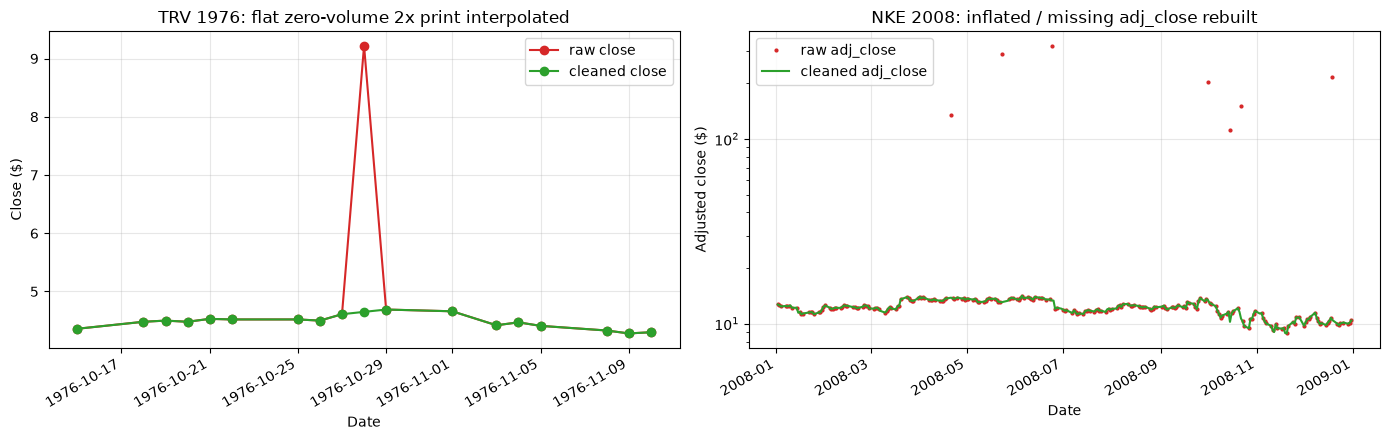

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
win = ("1976-10-15", "1976-11-10")
before = diag.query("ticker == 'TRV' and @win[0] <= ts <= @win[1]")
after = cleaned.query("ticker == 'TRV' and @win[0] <= ts <= @win[1]")
axes[0].plot(pd.to_datetime(before["ts"]), before["close"], "o-", color="tab:red", label="raw close")
axes[0].plot(pd.to_datetime(after["ts"]), after["close"], "o-", color="tab:green", label="cleaned close")
axes[0].set(title="TRV 1976: flat zero-volume 2x print interpolated", ylabel="Close ($)")

nke_b = diag.query("ticker == 'NKE' and '2008-01-01' <= ts <= '2008-12-31'")
nke_a = cleaned.query("ticker == 'NKE' and '2008-01-01' <= ts <= '2008-12-31'")
axes[1].plot(pd.to_datetime(nke_b["ts"]), nke_b["adj_close"], ".", color="tab:red", ms=4, label="raw adj_close")
axes[1].plot(pd.to_datetime(nke_a["ts"]), nke_a["adj_close"], "-", color="tab:green", label="cleaned adj_close")
axes[1].set(title="NKE 2008: inflated / missing adj_close rebuilt", ylabel="Adjusted close ($)", yscale="log")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
    ax.set_xlabel("Date")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 1.7 Save `ohlc_hw_cleaned` and verify with SQL

The cleaned table keeps `ts` as ISO `YYYY-MM-DD` text (so SQL `BETWEEN` date filters work), the original
`ticker_raw` label, and every repair/review flag. Quarantined rows and the pre-repair quality report are
saved alongside for audit. The raw `ohlc_hw` table is not touched.

In [30]:
import json
from datetime import datetime, timezone

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
CONFIG = {"factor_tol": FACTOR_TOL, "factor_jump_tol": FACTOR_JUMP_TOL, "neighbour_tol": NEIGHBOUR_TOL,
          "factor_min_cluster": FACTOR_MIN_CLUSTER, "factor_cluster_gap_days": FACTOR_CLUSTER_GAP_DAYS,
          "fill_limit": FILL_LIMIT, "outlier_rule": "abs(r - mean) > 3 * std(ddof=1), per ticker, gap-aware"}
CLEAN_COLUMNS = (["ts", "ticker", "ticker_raw"] + ALL_PRICE_COLS + ["volume"] + REPAIR_FLAGS
                 + ["bar_donor_ts", "adj_repair_reason", "extreme_return_flag_raw", "extreme_return_flag", "zero_volume_flag",
                    "weekend_flag"])
to_save = cleaned[CLEAN_COLUMNS].sort_values(["ticker", "ts"]).assign(cleaning_run_id=RUN_ID)
assert to_save["ts"].str.fullmatch(r"\d{4}-\d{2}-\d{2}").all()

with sqlite3.connect(DB_PATH) as conn:
    to_save.to_sql(CLEAN_TABLE, conn, if_exists="replace", index=False)
    quarantine_cols = [c for c in CLEAN_COLUMNS + ["reason"] if c in quarantined.columns]
    quarantined[quarantine_cols].to_sql(QUARANTINE_TABLE, conn, if_exists="replace", index=False)
    quality_report.to_sql(REPORT_TABLE, conn, if_exists="replace", index=False)          # before repairs
    # Lineage: everything needed to explain this run without re-executing the notebook.
    post_report.to_sql("ohlc_hw_final_report", conn, if_exists="replace", index=False)    # after repairs
    approved.to_sql("ohlc_hw_approved_exceptions", conn, if_exists="replace", index=False)
    stage_log.reset_index().to_sql("ohlc_hw_stage_log", conn, if_exists="replace", index=False)
    ticker_audit.to_sql("ohlc_hw_ticker_audit", conn, if_exists="replace", index=False)
    pd.DataFrame([{"run_id": RUN_ID, "raw_rows": RAW_ROW_COUNT, "retained": len(to_save),
                   "quarantined": len(quarantined), "config": json.dumps(CONFIG)}]) \
        .to_sql("ohlc_hw_cleaning_runs", conn, if_exists="append", index=False)
    conn.execute(f"CREATE UNIQUE INDEX IF NOT EXISTS idx_{CLEAN_TABLE}_key ON {CLEAN_TABLE}(ticker, ts)")
print(f"Saved {len(to_save):,} rows to {CLEAN_TABLE}, {len(quarantined)} to {QUARANTINE_TABLE}")

Saved 368,099 rows to ohlc_hw_cleaned, 152 to ohlc_hw_quarantine


In [31]:
checks_sql = f'''
SELECT
  COUNT(*)                                                        AS rows,
  COUNT(DISTINCT ticker || '|' || ts)                             AS unique_keys,
  COUNT(DISTINCT ticker)                                          AS tickers,
  SUM(open IS NULL OR high IS NULL OR low IS NULL OR close IS NULL OR adj_close IS NULL) AS null_prices,
  SUM(MIN(open, high, low, close, adj_close) <= 0)                AS nonpositive_prices,
  SUM(low > MIN(open, close) OR high < MAX(open, close))          AS bad_bars,
  SUM(volume IS NULL OR volume < 0)                               AS bad_volume,
  SUM(ts NOT GLOB '[0-9][0-9][0-9][0-9]-[0-9][0-9]-[0-9][0-9]')  AS non_iso_dates,
  MIN(ts) AS first_date, MAX(ts) AS last_date
FROM {CLEAN_TABLE}
'''
with sqlite3.connect(DB_PATH) as conn:
    sql_checks = pd.read_sql_query(checks_sql, conn)
    raw_rows_now = pd.read_sql_query(f"SELECT COUNT(*) AS n FROM {RAW_TABLE}", conn)["n"].iloc[0]
    roundtrip = pd.read_sql_query(f"SELECT * FROM {CLEAN_TABLE} ORDER BY ticker, ts", conn)

row = sql_checks.iloc[0]
assert row["rows"] == row["unique_keys"] == len(cleaned)
assert row[["null_prices", "nonpositive_prices", "bad_bars", "bad_volume", "non_iso_dates"]].sum() == 0
assert raw_rows_now == RAW_ROW_COUNT, "raw table must stay unchanged"
assert np.allclose(roundtrip["adj_close"], to_save["adj_close"].to_numpy())
sql_checks

,rows,unique_keys,tickers,null_prices,nonpositive_prices,bad_bars,bad_volume,non_iso_dates,first_date,last_date
0,368099,368099,30,0,0,0,0,0,1962-01-02,2024-12-06


## Summary of cleaning decisions

| Issue | Found | Decision |
|---|---|---|
| HTML / formatting in tickers | 150 labels → 30 tickers | Normalize before grouping; keep `ticker_raw` + audit table |
| Exact duplicates | 29,460 rows | Removed (no information lost) |
| Conflicting `(ticker, ts)` | 0 | Would be quarantined, never "keep first" |
| Missing trading days | 0 vs per-ticker `ohlc` calendar | Reported zero; detector proven on injected gap |
| Missing `adj_close` | 18,374 cells (after dedup) | Rebuilt as `close × same-date reference factor` |
| Inflated `adj_close` (4–24×) | 10,417 cells | Detected internally + confirmed vs reference; rebuilt the same way |
| `open = 0` on first day (5 tickers) | 5 rows | Leading gap with no earlier price → quarantined |
| Flat zero-volume bad prints (TRV ×3, AXP ×1) | 4 rows | Confirmed errors (reversal + bad-print bar) → interpolated; factor bridged from agreeing neighbours |
| Other 3σ returns | thousands | Kept, `extreme_return_flag` (e.g. JPM 2009, AAPL 2000: evidence of genuine trading, causes unverified; MCD 1968 possibly an unadjusted split — uncertain) |
| Zero volume | 75 rows (after dedup) | Kept, `zero_volume_flag` (prices are valid) |
| Weekend-dated observations | 384 rows, 1974-01 to 1975-04 (362 retained; 22 fell inside the quarantined DIS spans) | Kept, `weekend_flag`; same dates in the reference, no exchange calendar to settle it |
| Reference factor inconsistencies | 7 isolated days + 2 DIS spans (1974–75), all pre-1991 | Quarantined as unresolved: isolated days alone, clustered jumps as whole spans |

`ohlc_hw_cleaned` is now ready for the Part 2 report template.